# 06. Diagnóstico de datos, hiperparámetros y máquinas de vectores de soporte

## Pregunta de investigación

¿Qué parte del desempeño depende del tratamiento y selección de datos, de los cambios temporales y del ajuste de hiperparámetros, manteniendo una población de evaluación definida?

Esta fase contrasta hipótesis posteriores al primer experimento. **2015/2016 ya fueron observados**: sus nuevas predicciones son benchmarks retrospectivos reutilizados, no una nueva prueba final independiente. La población principal son préstamos aceptados a 36 meses; el archivo no representa directamente solicitantes rechazados. No se asignan etiquetas de pago/incumplimiento a préstamos activos. El informe académico sigue pendiente.

Este notebook lee resultados guardados. Su ejecución no vuelve a ajustar modelos ni a buscar configuraciones.

In [1]:
from pathlib import Path
import json
import pandas as pd
from IPython.display import display, Image
ROOT=Path.cwd()
if ROOT.name=='notebooks': ROOT=ROOT.parent
OUT=ROOT/'outputs\\research_v2'
pd.set_option('display.max_columns',16)
pd.set_option('display.max_rows',35)
protocol=json.loads((ROOT/'experiments'/'protocol_v2.json').read_text(encoding='utf-8'))
conclusion=json.loads((OUT/'conclusions.json').read_text(encoding='utf-8'))

## 1. Faltantes y valores inválidos

La auditoría revisa ingreso no positivo, deuda/utilización negativas, FICO fuera del dominio o con límites inconsistentes y monto no positivo. Son reglas concretas, no una certificación de calidad de todas las columnas. Los valores plausibles extremos se estudian separadamente mediante clipping ajustado con entrenamiento.

Se identifican 17 columnas constantes o con más de 95% de ausencia en el entrenamiento anterior. Varias comenzaron a estar disponibles en años posteriores. Una columna completamente vacía no enseña una relación útil, pero puede afectar indirectamente a una variable derivada que cuenta ausentes. Esto motiva una ablación y una prueba de sensibilidad; no demuestra automáticamente una mejora predictiva.

La imputación por mediana con indicadores se compara con el tratamiento nativo de ausentes. No se supone que rellenar todo sea superior: ausencia de una mora previa y ausencia de un campo nuevo pueden tener significados distintos.

In [2]:
invalid=pd.read_csv(OUT/'invalid_by_year.csv')
summary=invalid.query('year<=2015').groupby('rule')[['n','invalid_n']].sum()
summary['fraction']=summary.invalid_n/summary.n
display(summary)
print(json.loads((OUT/'audit_findings.json').read_text(encoding='utf-8'))['unlearnable_or_95pct_missing_in_old_training'])

,n,invalid_n,fraction
rule,,,
dti_negative,887440,0,0.000000
fico_low_exceeds_high,887440,0,0.000000
fico_outside_300_850,887440,0,0.000000
income_nonpositive,887440,2,0.000002
loan_amnt_nonpositive,887440,0,0.000000
revol_util_negative,887440,0,0.000000


['annual_inc_joint', 'dti_joint', 'open_acc_6m', 'open_act_il', 'open_il_12m', 'open_il_24m', 'mths_since_rcnt_il', 'total_bal_il', 'il_util', 'open_rv_12m', 'open_rv_24m', 'max_bal_bc', 'all_util', 'inq_fi', 'total_cu_tl', 'inq_last_12m', 'application_type']


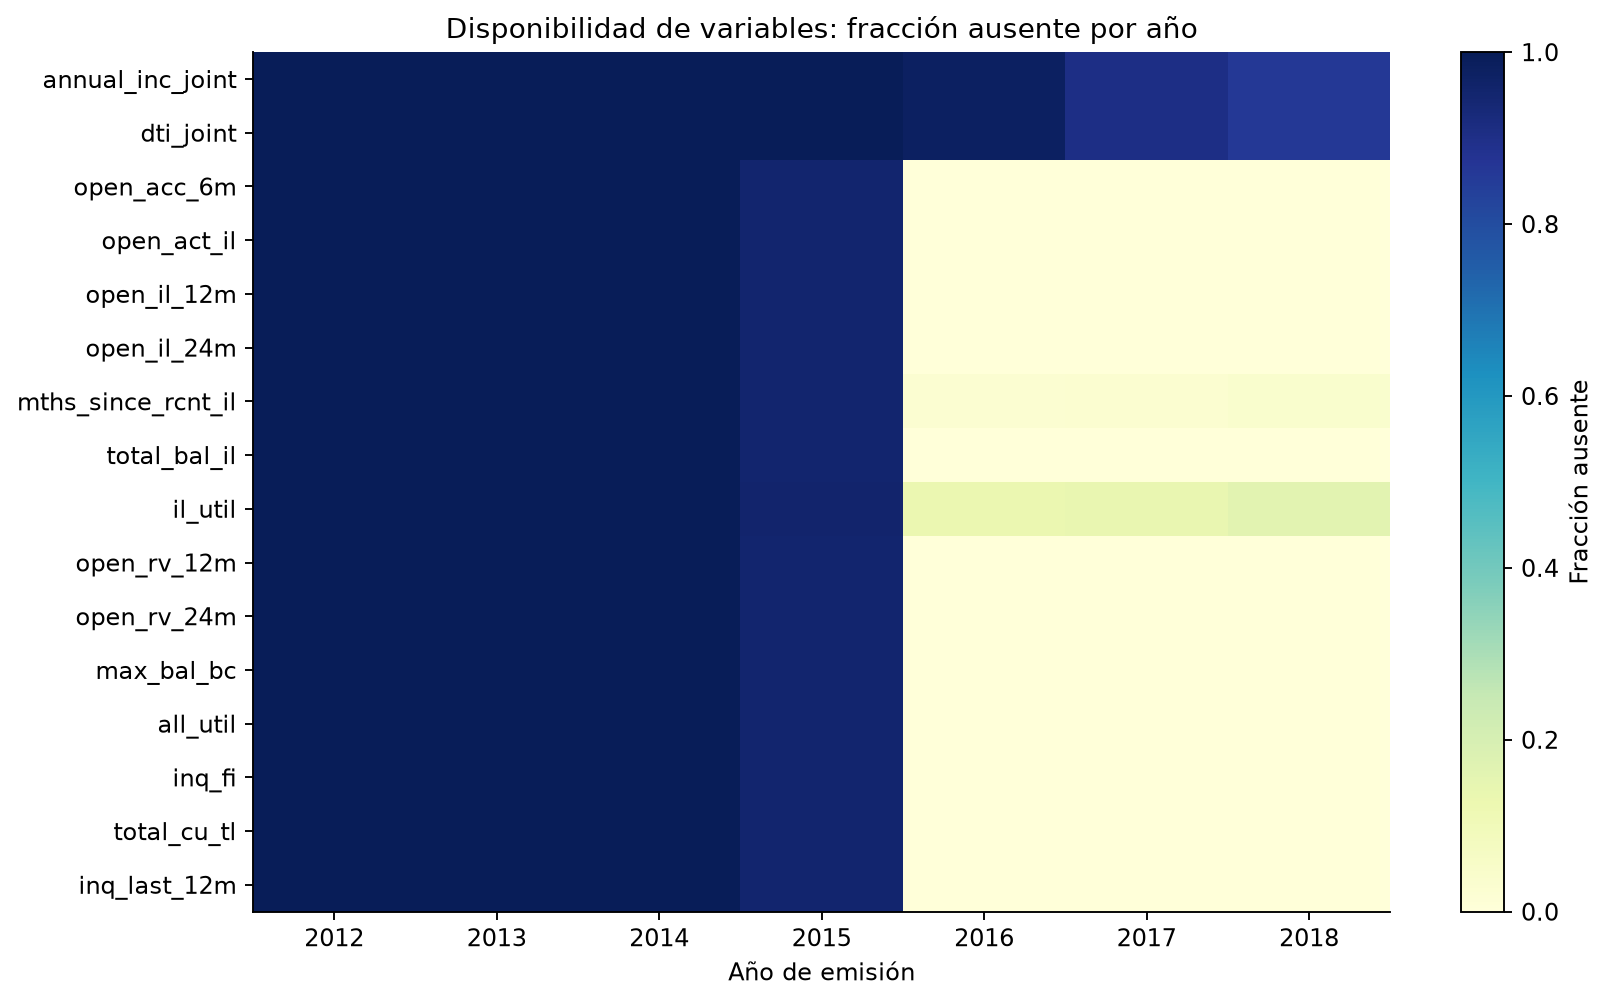

In [3]:
display(Image(filename=str(OUT/'figures'/'disponibilidad_variables.png')))

## 2. Préstamos activos: cobertura y límites de identificación

Las coberturas siguientes corresponden al censo de la fuente, antes de excluir IDs de la muestra inicial; por eso difieren ligeramente de las coberturas de la prueba original.

La tasa entre préstamos terminados no identifica la tasa final de todos los emitidos. Para mostrar qué se sabe sin inventar etiquetas, se calculan límites: mínimo = incumplimientos conocidos / aceptados; máximo = (incumplimientos conocidos + no terminales) / aceptados. No son intervalos de confianza, sino extremos lógicos sin supuestos adicionales. Que un préstamo permanezca activo no significa que sea malo.

La cohorte 2015 a 36 meses tiene seguimiento casi completo. Las cohortes 2017/2018 no ofrecen una prueba madura para este objetivo. Seleccionar solamente sus resultados conocidos favorece casos que terminaron pronto.

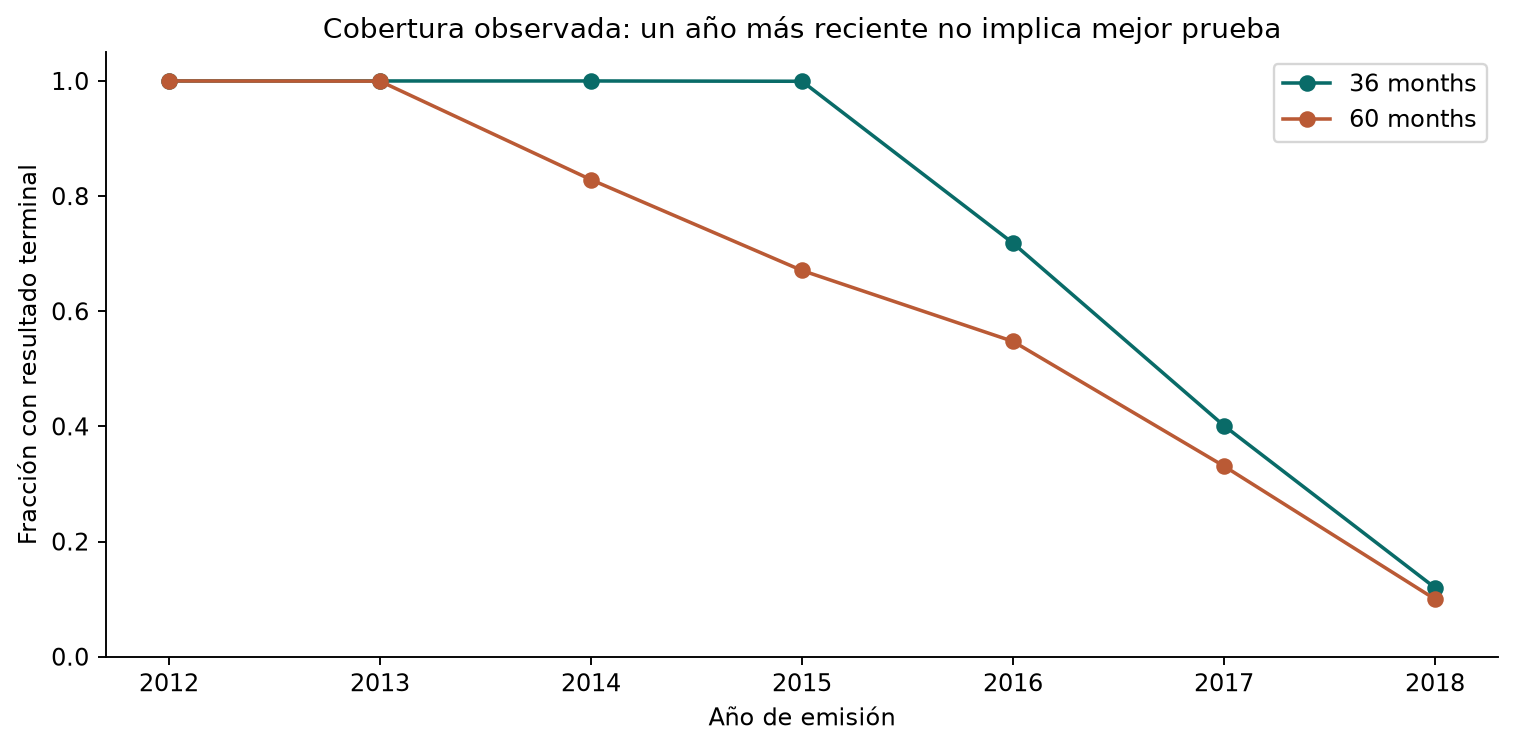

In [4]:
display(Image(filename=str(OUT/'figures'/'cobertura.png')))

In [5]:
coverage=pd.read_csv(OUT/'outcome_coverage_bounds.csv')
display(coverage.query('year>=2013'))

,year,term,accepted_n,resolved_n,nonterminal_n,terminal_fraction,conditional_default_rate,all_accepted_default_lower_bound,all_accepted_default_upper_bound
9,2013,36 months,100422,100422,0,1.000000,0.123260,0.123260,0.123260
10,2013,60 months,34392,34382,10,0.999709,0.251469,0.251396,0.251686
11,2014,36 months,162570,162570,0,1.000000,0.137264,0.137264,0.137264
12,2014,60 months,73059,60532,12527,0.828536,0.311339,0.257956,0.429420
13,2015,36 months,283173,283026,147,0.999481,0.148863,0.148785,0.149304
14,2015,60 months,137922,92519,45403,0.670807,0.363936,0.244131,0.573324
15,2016,36 months,323495,232353,91142,0.718258,0.198457,0.142543,0.424285
16,2016,60 months,110912,60742,50170,0.547659,0.364328,0.199528,0.651868
17,2017,36 months,320419,128538,191881,0.401156,0.200104,0.080273,0.679117
18,2017,60 months,123160,40762,82398,0.330968,0.329400,0.109021,0.778053


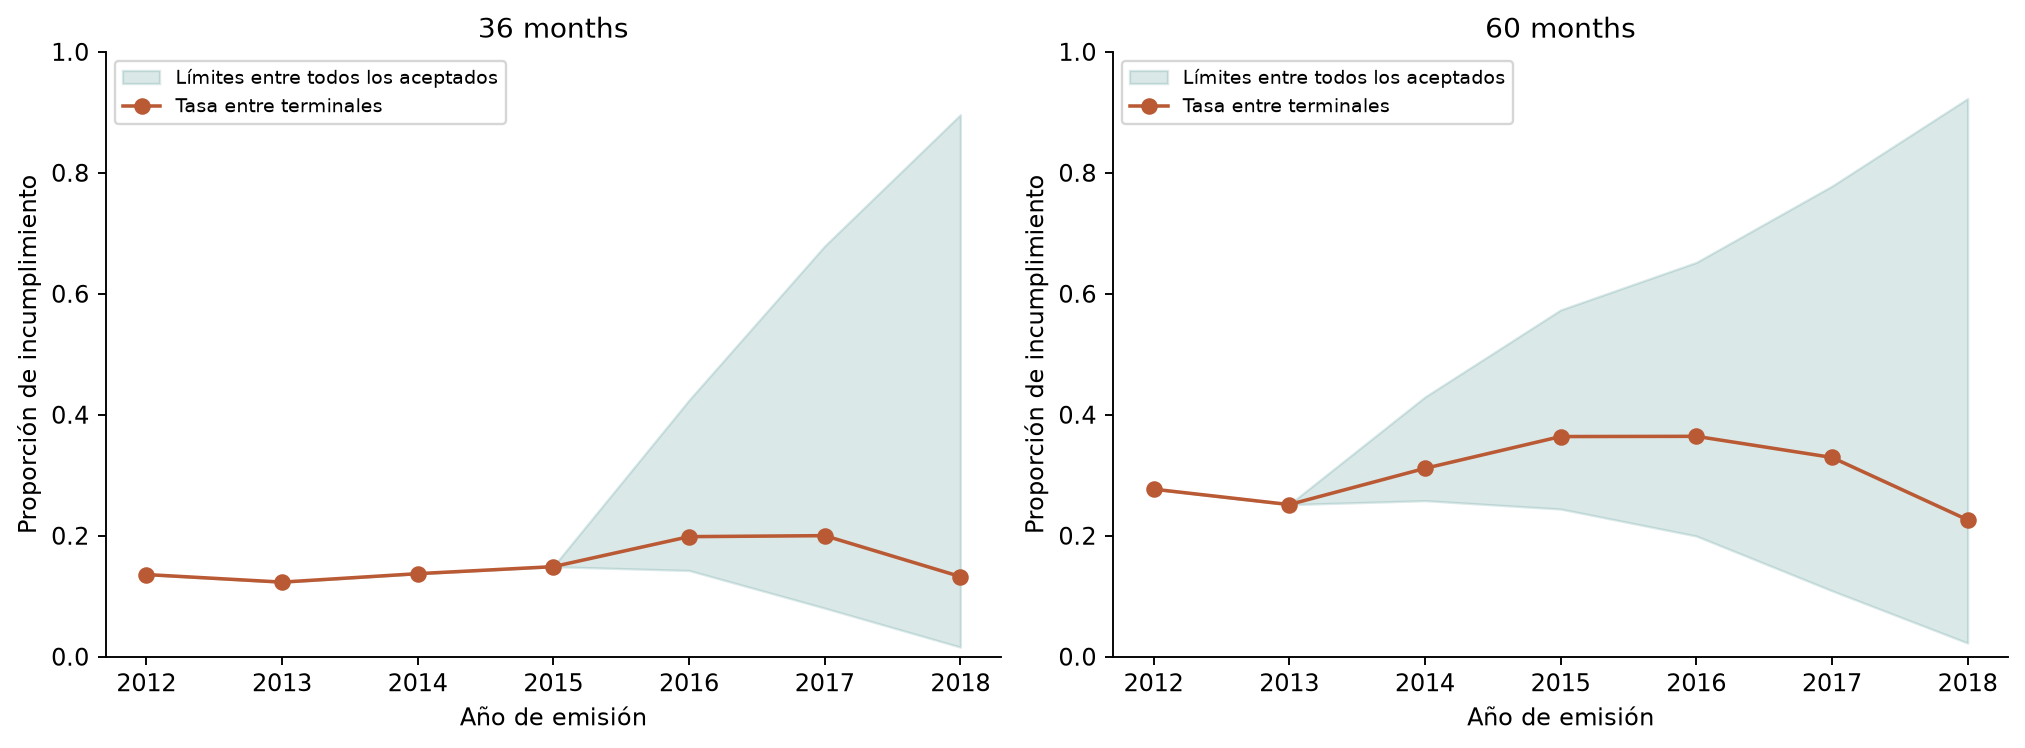

In [6]:
display(Image(filename=str(OUT/'figures'/'tasas_y_limites.png')))

La cobertura también se revisa por mes. Como sensibilidad secundaria se eligen meses de emisión de 2016 a 36 meses con cobertura terminal de al menos 99,5% en el censo de la fuente, antes de excluir la muestra inicial. La selección se basa en seguimiento, no en AP. Esto permite comparar cohortes más maduras sin convertirlas en pruebas nuevas independientes: sus préstamos ya estaban en el benchmark anterior.

In [7]:
monthly=pd.read_csv(OUT/'monthly_outcome_coverage.csv')
display(monthly[monthly.issue_month.str.startswith('2016') & monthly.term.eq('36 months')])
print(json.loads((OUT/'secondary_mature_months.json').read_text(encoding='utf-8')))

,issue_month,term,accepted_n,terminal_n,terminal_fraction,nonterminal_n,conditional_default_rate,all_accepted_default_lower_bound,all_accepted_default_upper_bound
171,2016-01,36 months,22675,22532,0.993693,143,0.143485,0.142580,0.148886
173,2016-02,36 months,28609,28163,0.984411,446,0.152292,0.149918,0.165507
175,2016-03,36 months,44836,39089,0.871822,5747,0.177441,0.154697,0.282875
177,2016-04,36 months,28106,19451,0.692059,8655,0.227135,0.157191,0.465132
179,2016-05,36 months,21831,14660,0.671522,7171,0.239291,0.160689,0.489167
181,2016-06,36 months,24600,16190,0.658130,8410,0.205374,0.135163,0.477033
183,2016-07,36 months,25375,16587,0.653675,8788,0.233737,0.152788,0.499113
185,2016-08,36 months,27181,17354,0.638461,9827,0.230667,0.147272,0.508811
187,2016-09,36 months,21342,13228,0.619811,8114,0.218174,0.135226,0.515416
189,2016-10,36 months,24746,14823,0.599006,9923,0.200432,0.120060,0.521054


{'rule': '2016 36-month source cohorts with terminal coverage >= 0.995; no model performance used to choose months', 'months': [], 'coverage_threshold': 0.995, 'independent_pristine_test': False, 'source_population_before_initial_sample_exclusion': True}


## 3. Diferencias entre años y selección de población

La frecuencia de incumplimiento a 36 meses aumenta entre 2013 y 2015, años con cobertura completa o casi completa. Eso documenta diferencias entre cohortes, sin identificar su causa. En 2016 y posteriores, la censura impide interpretar la tasa condicionada a terminar como si fuera la tasa final de todos los préstamos.

Se comparan ingreso, deuda, FICO, utilización y cuentas por año, plazo y estado terminal. La diferencia media estandarizada (SMD) describe diferencias observables; no prueba causalidad ni corrige la selección. Las diferencias de seguimiento y de variables pueden coexistir.

In [8]:
smd=pd.read_csv(OUT/'selection_bias_smd.csv')
display(smd.query("year==2015 and term=='60 months'"))
features=pd.read_csv(OUT/'population_features_by_year_term_status.csv')
display(features.query("year>=2013 and term=='36 months' and terminal==True and feature in ['annual_inc','dti','fico_range_low']")[[ 'year','feature','n','median','q10','q90','missing']])
print('Cambio de covariables entre todos los aceptados a 36 meses, sin condicionar a terminar:')
display(pd.read_csv(OUT/'temporal_population_shift.csv'))

,year,term,feature,SMD_terminal_minus_nonterminal,terminal_n,nonterminal_n
56,2015,60 months,annual_inc,-0.016508,92519,45403
57,2015,60 months,dti,-0.054342,92519,45403
58,2015,60 months,fico_range_low,-0.057262,92519,45403
59,2015,60 months,loan_amnt,0.008729,92519,45403
60,2015,60 months,open_acc,0.034721,92519,45403
61,2015,60 months,revol_util,-0.178874,92519,45403
62,2015,60 months,total_acc,0.150839,92519,45403


,year,feature,n,median,q10,q90,missing
98,2013,annual_inc,100422,60000.00,32000.00,120000.000000,0.000000
99,2013,dti,100422,16.41,6.95,27.490000,0.000000
101,2013,fico_range_low,100422,690.00,665.00,730.000000,0.000000
119,2014,annual_inc,162570,60000.00,31288.10,120000.000000,0.000000
120,2014,dti,162570,17.05,7.20,28.650000,0.000000
122,2014,fico_range_low,162570,685.00,660.00,735.000000,0.000000
147,2015,annual_inc,283026,62000.00,32000.00,125000.000000,0.000000
148,2015,dti,283026,17.87,7.43,30.389999,0.000007
150,2015,fico_range_low,283026,685.00,660.00,735.000000,0.000000


Cambio de covariables entre todos los aceptados a 36 meses, sin condicionar a terminar:


,feature,reference_year,comparison_year,population,reference_n,comparison_n,SMD,KS_distance,PSI_train_bins,median_2014,median_2015,missing_2014,missing_2015
0,annual_inc,2014,2015,"all accepted 36-month loans, including active ...",162570,283173,0.029884,0.012813,0.001248,60000.000000,62000.000000,0.000000,0.000000
1,dti,2014,2015,"all accepted 36-month loans, including active ...",162570,283173,0.108915,0.042950,0.014956,17.049999,17.879999,0.000000,0.000007
2,loan_amnt,2014,2015,"all accepted 36-month loans, including active ...",162570,283173,0.027780,0.018896,0.002754,10000.000000,10000.000000,0.000000,0.000000
3,fico_range_low,2014,2015,"all accepted 36-month loans, including active ...",162570,283173,0.036568,0.016124,0.001437,685.000000,685.000000,0.000000,0.000000
4,revol_util,2014,2015,"all accepted 36-month loans, including active ...",162570,283173,-0.074262,0.037539,0.008105,54.200001,52.200001,0.000474,0.000445
5,open_acc,2014,2015,"all accepted 36-month loans, including active ...",162570,283173,0.036943,0.018376,0.003764,10.000000,11.000000,0.000000,0.000000
6,total_acc,2014,2015,"all accepted 36-month loans, including active ...",162570,283173,-0.055985,0.027167,0.004658,24.000000,23.000000,0.000000,0.000000


## 4. ¿La muestra inicial era poco representativa?

Se separan dos poblaciones: todos los resultados terminales y todos los préstamos aceptados. La distancia de variación total (TVD) vale cero cuando las distribuciones coinciden; aumenta con su diferencia. Aquí se compara año, plazo y estado.

La muestra aleatoria de 115.000 reproduce de cerca las distribuciones de la población terminal de la que se extrajo. La diferencia frente a todos los aceptados es mucho mayor, especialmente por año. El problema no es necesariamente haber tomado una muestra aleatoria: es extrapolar una muestra de préstamos terminados a otra población. La TVD de unas pocas variables no demuestra representatividad conjunta completa.

In [9]:
display(pd.read_csv(OUT/'sample_representativeness.csv'))

,population,dimension,TVD
0,all_terminal_2007_2018,issue_year,0.002714
1,all_accepted_2007_2018,issue_year,0.246838
2,all_terminal_2007_2018,term,0.000415
3,all_accepted_2007_2018,term,0.047086
4,all_terminal_2007_2018,loan_status,0.000730


También se comparan ingresos, DTI, monto, FICO, utilización y cuentas, además de vivienda, propósito, verificación y tipo de solicitud, contra la población terminal de la fuente hasta 2015 y dentro de 2015 a 36 meses. Se muestran diferencias estandarizadas de medias (SMD), distancia KS y TVD categórica. La muestra es parte del censo de referencia: son distancias descriptivas, sin pruebas de significación que supongan muestras independientes. Estas variables amplían la auditoría marginal; no certifican representatividad de toda combinación de características.

In [10]:
display(pd.read_csv(OUT/'sample_feature_representativeness.csv'))

,scope,feature,type,source_n,sample_n,SMD_sample_minus_source,KS_distance,TVD,missing_source,missing_sample
0,terminal_through_2015,annual_inc,numeric,826604,70626,0.003695,0.002386,NaN,0.000000,0.000000
1,terminal_through_2015,dti,numeric,826604,70626,-0.000228,0.002213,NaN,0.000002,0.000000
2,terminal_through_2015,loan_amnt,numeric,826604,70626,-0.002846,0.002305,NaN,0.000000,0.000000
3,terminal_through_2015,fico_range_low,numeric,826604,70626,-0.002238,0.001991,NaN,0.000000,0.000000
4,terminal_through_2015,revol_util,numeric,826604,70626,0.005941,0.006087,NaN,0.000537,0.000581
5,terminal_through_2015,open_acc,numeric,826604,70626,-0.008613,0.003128,NaN,0.000000,0.000000
6,terminal_through_2015,total_acc,numeric,826604,70626,-0.006562,0.002812,NaN,0.000000,0.000000
7,terminal_through_2015,home_ownership,categorical,826604,70626,NaN,NaN,0.001505,NaN,NaN
8,terminal_through_2015,purpose,categorical,826604,70626,NaN,NaN,0.002707,NaN,NaN
9,terminal_through_2015,verification_status,categorical,826604,70626,NaN,NaN,0.001215,NaN,NaN


## 5. Recetas y ablaciones de datos

Con parámetros de LightGBM fijos se comparan nueve recetas. La validación siempre contiene préstamos a 36 meses de las mismas fechas; cambian las filas de entrenamiento y el tratamiento de variables. Las recetas estables eliminan columnas no aprendibles, ajustan el conteo de ausentes a campos disponibles en entrenamiento y eliminan derivados redundantes. Algunas recetas combinan factores; por eso se añade una ablación separada que cambia un factor a la vez.

Los recortes por cuantiles, medianas y selección de columnas se aprenden exclusivamente con entrenamiento. Dos cortes permiten una comprobación inicial; diferencias pequeñas no deben describirse como evidencia universal o causal.

La auditoría adicional observó aproximadamente 52% de ausencia en 2012 para saldo total, límite revolvente y cuentas revolventes, frente a 0% en 2013. Antes de generar nuevas predicciones del benchmark se añadieron variantes de entrenamiento desde 2013 para contrastar esa disponibilidad. CatBoost y LightGBM conservan sus parámetros anteriores; las variantes SVM conservan sus parámetros ajustados. Se seleccionan sobre la misma validación Q3. Este control de fecha cambia filas de entrenamiento, no la población de evaluación, y no implica que usar menos datos sea siempre mejor.

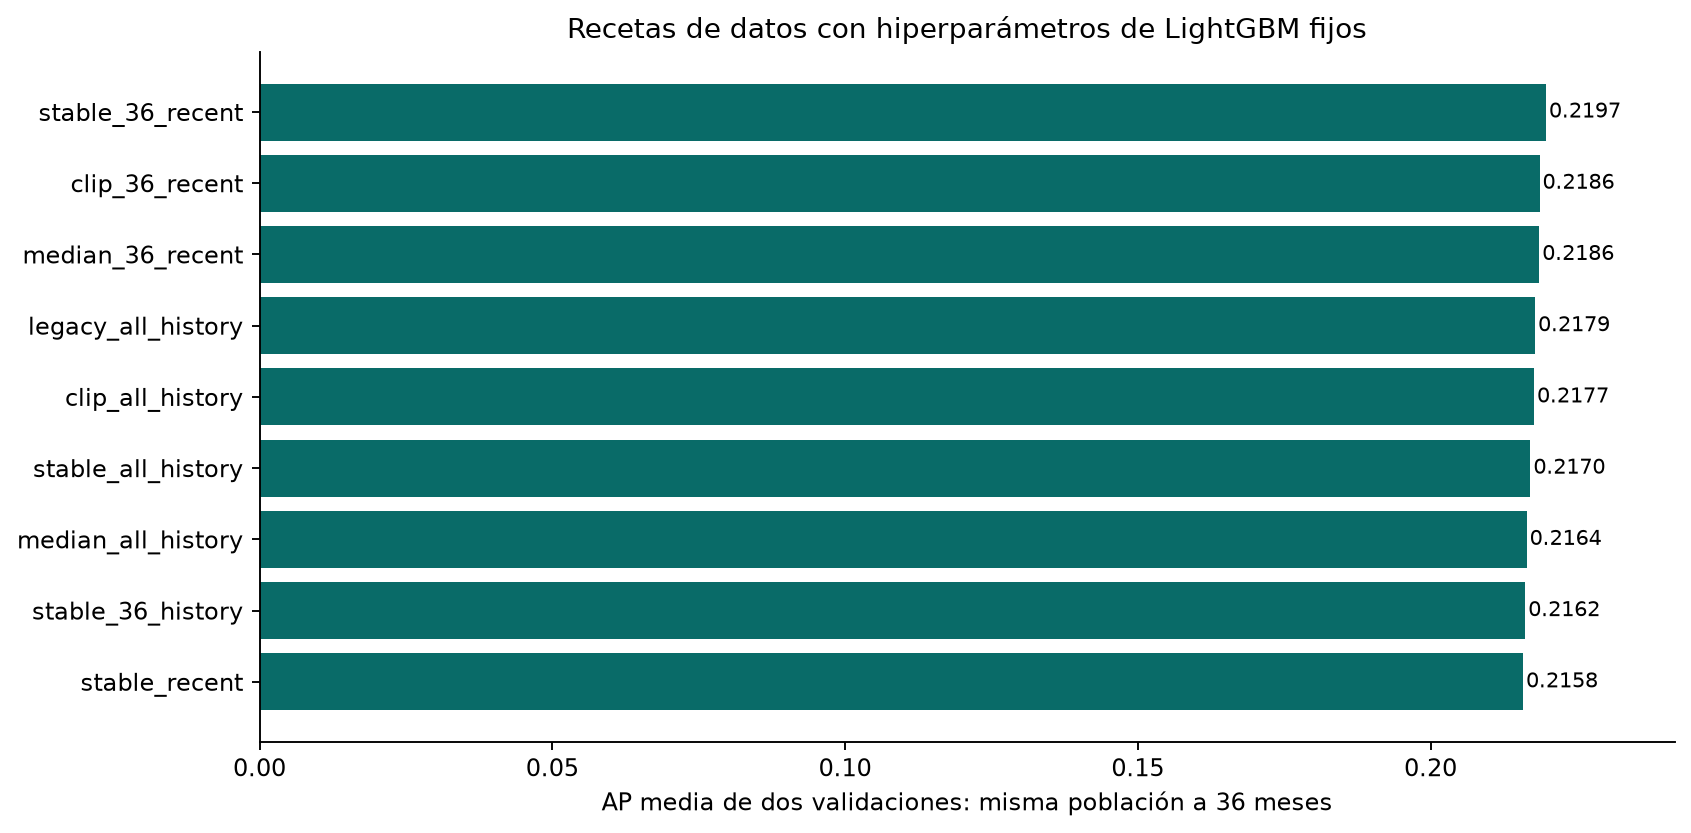

In [11]:
display(Image(filename=str(OUT/'figures'/'recetas_cv.png')))

In [12]:
display(pd.read_csv(OUT/'recipe_screen.csv').sort_values('CV_AP',ascending=False))
print('Receta base del cribado:',conclusion['screened_recipe'])
print('Receta del modelo elegido finalmente en validación:',conclusion['recipe'])
print('Control adicional desde 2013:',json.loads((OUT/'availability_2013_cv.json').read_text(encoding='utf-8')))

,recipe,CV_AP,fold1_AP,fold2_AP
6,stable_36_recent,0.219711,0.210374,0.229047
8,clip_36_recent,0.218611,0.211408,0.225815
7,median_36_recent,0.218560,0.210878,0.226242
0,legacy_all_history,0.217851,0.211198,0.224505
3,clip_all_history,0.217670,0.209858,0.225483
1,stable_all_history,0.217049,0.211605,0.222494
2,median_all_history,0.216413,0.211853,0.220974
4,stable_36_history,0.216170,0.210109,0.222232
5,stable_recent,0.215795,0.207510,0.224080


Receta base del cribado: {'name': 'stable_36_recent', 'mode': 'stable', 'term': '36 months', 'start': '2012-01-01'}
Receta del modelo elegido finalmente en validación: {'name': 'stable_36_recent', 'mode': 'stable', 'term': '36 months', 'start': '2012-01-01'}


Control adicional desde 2013: {'recipe': {'name': 'stable_36_recent_from_2013', 'mode': 'stable', 'term': '36 months', 'start': '2013-01-01'}, 'fixed_previous_lightgbm_params': True, 'CV_AP': 0.21876779918812508, 'fold_AP': [0.21012779209567808, 0.22740780628057208], 'fold_ROC_AUC': [0.6670733795843073, 0.6718222986135731], 'fold_iterations': [141, 93], 'fold_seconds': [5.08, 5.93], 'fold_records': [{'fold': 0, 'train_n': 41124, 'validation_n': 20000, 'train_ids_sha256': 'bf8032afad74adc085d25e27dcb3fbfd256f7ae495284ba02c363fbfd062d354', 'validation_ids_sha256': '5025bc85d9cc5f06c6f7298de69a35ddd2d0ef88e3aa0cfc9e5a7e4a23a853d3', 'feature_count': 76, 'AP': 0.21012779209567808, 'ROC_AUC': 0.6670733795843073}, {'fold': 1, 'train_n': 60000, 'validation_n': 20000, 'train_ids_sha256': 'f5bcb614ae1b84726ee8a3f0d6397cc69b5a07a4e9ac9e7a896a1f935021dc46', 'validation_ids_sha256': '27e5aac14b3a95c715af10dbfdb5ad84dd100434258dafed4e1c5c76116561f5', 'feature_count': 76, 'AP': 0.22740780628057208, '

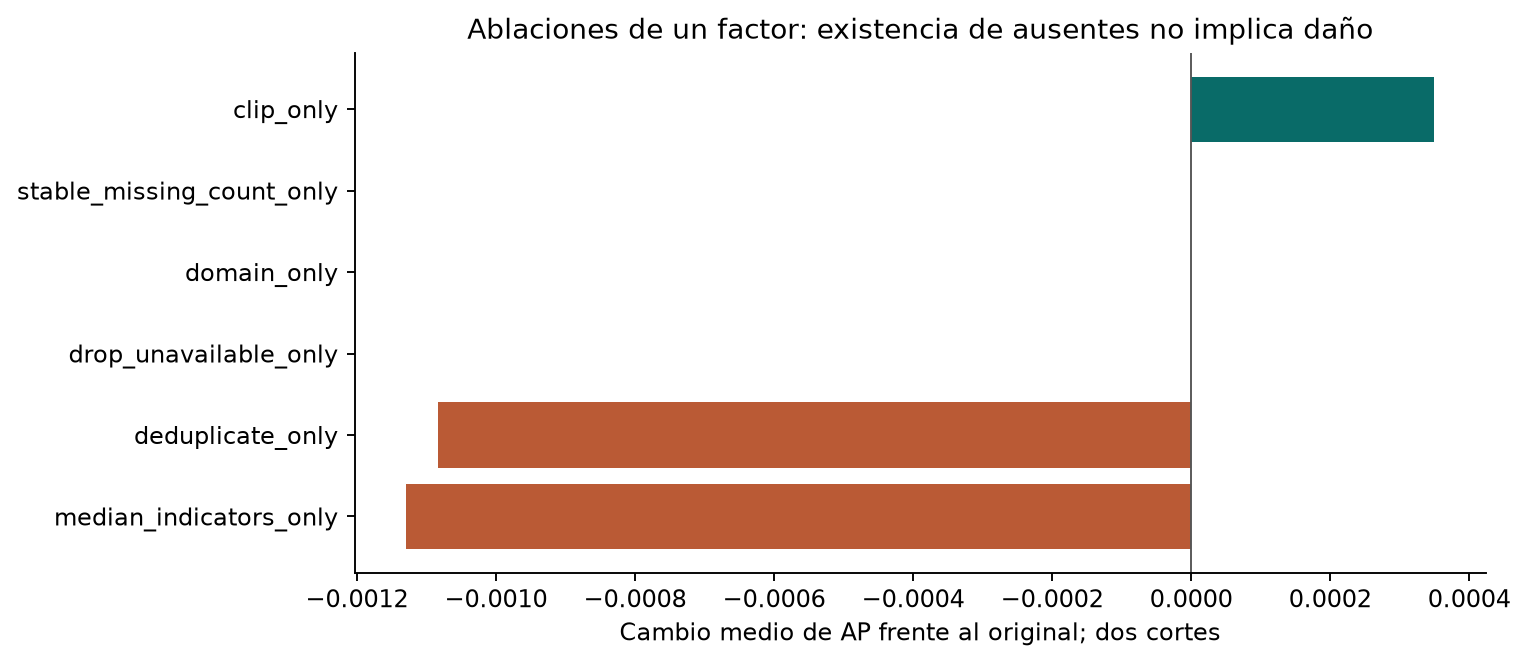

In [13]:
display(Image(filename=str(OUT/'figures'/'ablaciones_factor.png')))

In [14]:
display(pd.read_csv(OUT/'one_factor_ablation.csv').pivot(index='variant',columns='fold',values='AP'))

fold,0,1
variant,,
clip_only,0.212911,0.222845
deduplicate_only,0.210909,0.221980
domain_only,0.211096,0.223960
drop_unavailable_only,0.211096,0.223960
median_indicators_only,0.211493,0.221304
original,0.211096,0.223960
stable_missing_count_only,0.211096,0.223960


## 6. Hiperparámetros y SVM

Se ajustan LightGBM y CatBoost, y se añaden tres estrategias: **LinearSVC**, **SVC con RBF exacto** y **Nyström RBF + LinearSVC**. La última aproxima un kernel; no es SVC RBF exacta. SVM utiliza imputación, escalado y codificación ajustados en entrenamiento. Se exploran C, ponderación de clases y, en RBF, gamma; en Nyström también el número de componentes.

`C` controla la penalización de errores o violaciones del margen: valores altos pueden ajustar más el entrenamiento, pero requieren comprobar generalización. En RBF, `gamma` controla qué tan local es la influencia de los ejemplos. La ponderación balanceada modifica penalizaciones por clase; no garantiza probabilidades calibradas. La función de decisión de SVM es una puntuación de margen, no una probabilidad de incumplimiento.

La SVC exacta usa hasta 12.000 filas por su costo. Su búsqueda valida hasta 8.000 filas por corte; las otras estrategias utilizan hasta 60.000/20.000. Los CV con distinto presupuesto no son una comparación definitiva. La selección posterior utiliza toda la cohorte 2014 Q3 a 36 meses. Se incorpora además una comparación de todas las familias con exactamente las mismas 12.000 filas de entrenamiento. Las probabilidades SVM se calibran en un bloque temporal separado.

La predicción RBF exacta de 40.595 préstamos tardó entre 146 y 163 segundos. Antes de abrir las nuevas predicciones externas se fijó otro control de costo: **todos los modelos** se comparan sobre los mismos 20.000 préstamos estratificados por año, con semilla 42. Las variantes RBF exactas no seleccionadas se evalúan solo en esa muestra común. Los demás modelos, y siempre el ganador seleccionado en desarrollo, también se evalúan en la cohorte completa. Sus tablas se muestran separadas: AP de muestras distintas no se compara directamente.

Los intentos podados no completan necesariamente ambos cortes. Se selecciona entre intentos completos y se registran advertencias de convergencia. La regresión logística, Random Forest y XGBoost permanecen como comparadores con sus parámetros anteriores y la nueva receta.

In [15]:
families=['lightgbm','catboost','svm_linear','svm_rbf','svm_nystroem']
best=[json.loads((OUT/f'best_{f}.json').read_text(encoding='utf-8')) for f in families]
display(pd.DataFrame(best)[['family','CV_AP','trial_count','fold_AP']])
for row in best: print(row['family'],row['params'])
retry=json.loads((OUT/'svm_solver_retries.json').read_text(encoding='utf-8'))
print('Repeticiones adicionales de las mismas configuraciones RBF con mayor límite del solver:',len(retry['additional_same_configuration_solver_retries']))
display(pd.read_csv(OUT/'selection_leaderboard.csv').sort_values('AP',ascending=False))

,family,CV_AP,trial_count,fold_AP
0,lightgbm,0.222597,28,"[0.2154517785397429, 0.22974205042900062]"
1,catboost,0.224113,16,"[0.21622610011959484, 0.23199957943705124]"
2,svm_linear,0.215205,12,"[0.20861428333286797, 0.22179582390929514]"
3,svm_rbf,0.204489,12,"[0.19536406032090287, 0.2136145737481951]"
4,svm_nystroem,0.219017,12,"[0.21080423134740414, 0.22722939407867254]"


lightgbm {'n_estimators': 530, 'learning_rate': 0.02588968965098415, 'num_leaves': 15, 'min_child_samples': 273, 'reg_lambda': 2.462300726483128, 'reg_alpha': 0.0003745018823436387, 'colsample_bytree': 0.798070764044508, 'subsample': 0.6620359823903265, 'subsample_freq': 1, 'scale_pos_weight': 1.0}
catboost {'iterations': 1177, 'learning_rate': 0.02205578452420942, 'depth': 7, 'l2_leaf_reg': 54.12993362140874, 'random_strength': 1.9728817186293905, 'bagging_temperature': 0.6092275383467414, 'rsm': 0.6841852399022343, 'auto_class_weights': None}
svm_linear {'C': 0.0030605882806936423, 'class_weight': 'balanced'}
svm_rbf {'C': 0.2801635158716261, 'class_weight': 'balanced', 'gamma': 0.0028887015747659996, 'max_iter': 100000}
svm_nystroem {'C': 1.2649675876166606, 'class_weight': None, 'gamma': 0.0009187608485161292, 'n_components': 600}
Repeticiones adicionales de las mismas configuraciones RBF con mayor límite del solver: 3


,name,AP,ROC_AUC,train_n,validation_n,fit_predict_seconds,n_features
1,catboost,0.253568,0.692028,215847,40595,1.43,76
11,catboost_from_2013,0.252710,0.691826,172377,40595,195.82,76
6,catboost_previous_params,0.251283,0.690473,215847,40595,208.99,76
4,svm_nystroem,0.251163,0.691398,215847,40595,1.68,76
14,svm_nystroem_from_2013,0.250986,0.691204,172377,40595,79.64,76
0,lightgbm,0.250087,0.690459,215847,40595,2.34,76
7,logistic,0.246786,0.683094,215847,40595,23.47,76
5,lightgbm_previous_params,0.246629,0.687673,215847,40595,1.22,76
9,xgboost,0.245504,0.685952,215847,40595,26.96,76
12,svm_linear_from_2013,0.245475,0.684014,172377,40595,29.86,76


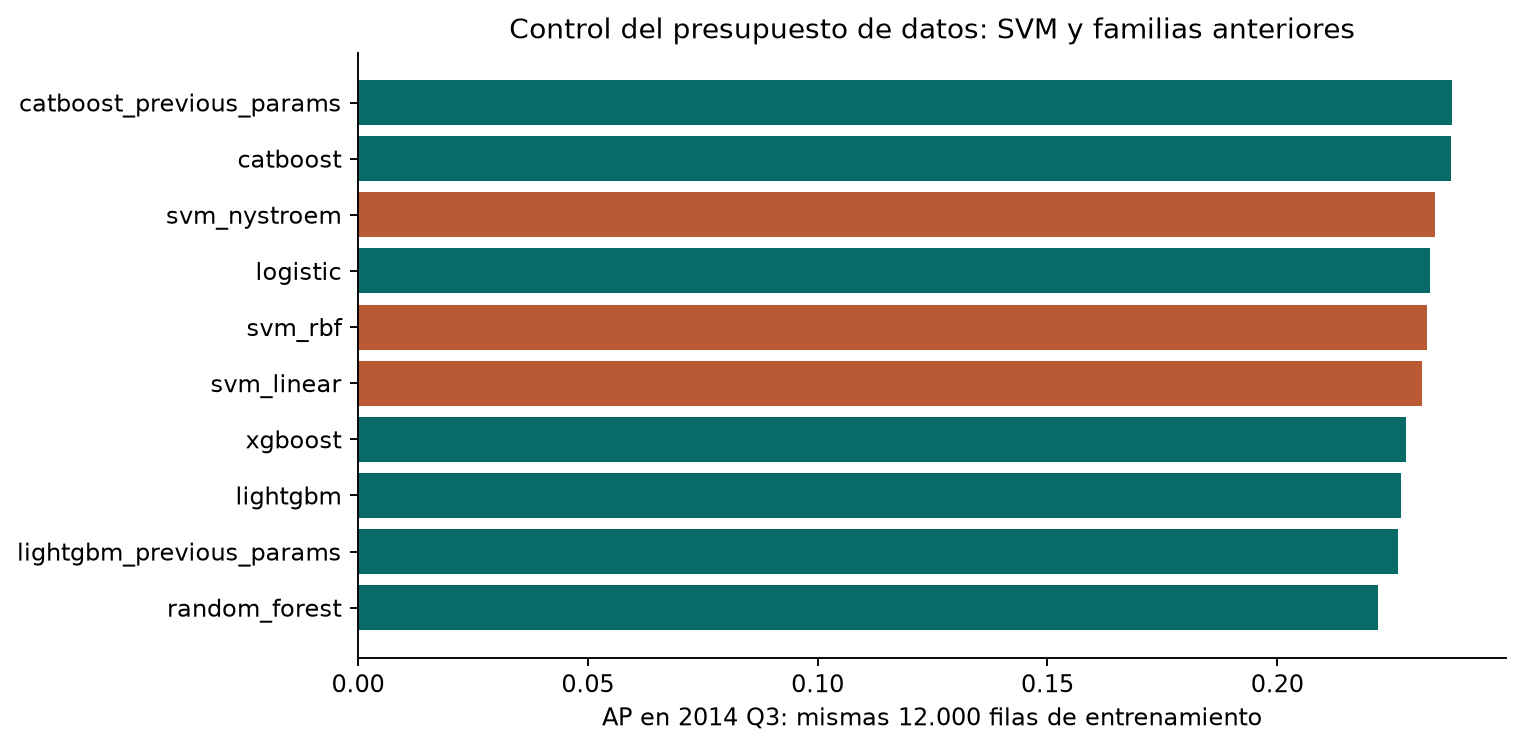

In [16]:
display(Image(filename=str(OUT/'figures'/'presupuesto_igual.png')))

In [17]:
display(pd.read_csv(OUT/'matched_budget_validation.csv').sort_values('AP',ascending=False))
display(pd.read_csv(OUT/'hyperparameter_controls_validation.csv'))
print('Efecto del tamaño de entrenamiento: mismas variables, parámetros y validación')
display(pd.read_csv(OUT/'training_size_validation.csv'))

,family,train_n,validation_n,AP,ROC_AUC,seconds,same_training_rows_for_all_models
6,catboost_previous_params,12000,40595,0.237971,0.674949,70.043696,True
1,catboost,12000,40595,0.237798,0.674886,132.961852,True
4,svm_nystroem,12000,40595,0.234247,0.668593,5.840089,True
7,logistic,12000,40595,0.233320,0.667311,2.281767,True
3,svm_rbf,12000,40595,0.232535,0.666514,173.076444,True
2,svm_linear,12000,40595,0.231422,0.666497,2.613140,True
9,xgboost,12000,40595,0.228020,0.666567,4.187746,True
0,lightgbm,12000,40595,0.226848,0.664832,6.257419,True
5,lightgbm_previous_params,12000,40595,0.226368,0.664290,2.833553,True
8,random_forest,12000,40595,0.221892,0.662517,6.652415,True


,family,setting,train_n,validation_n,AP,ROC_AUC,same_features_and_training_rows,diagnostic_not_used_to_reselect_after_benchmark
0,lightgbm,previous_parameters,215847,40595,0.246629,0.687673,True,True
1,lightgbm,new_search_parameters,215847,40595,0.250087,0.690459,True,True
2,catboost,previous_parameters,215847,40595,0.251283,0.690473,True,True
3,catboost,new_search_parameters,215847,40595,0.253568,0.692028,True,True


Efecto del tamaño de entrenamiento: mismas variables, parámetros y validación


,training_n,validation_n,AP,ROC_AUC,same_features_parameters_validation,not_used_to_reselect
0,12000,40595,0.226848,0.664832,True,True
1,30000,40595,0.241514,0.679898,True,True
2,60000,40595,0.243547,0.682270,True,True
3,215847,40595,0.250087,0.690459,True,True


## 7. Benchmark maduro reutilizado y comparación pareada

El ajuste definitivo llega a septiembre de 2014, la calibración se ajusta en octubre-noviembre y su método/umbral se eligen en diciembre. Es una separación temporal retrospectiva: las fechas históricas de disponibilidad de etiquetas no se pueden reconstruir completamente.

La comparación principal usa los mismos IDs a 36 meses de 2015 que la sensibilidad madura anterior. **No se compara su AP con 0,4164**, que correspondía a mezclar ambos plazos. El nuevo modelo fue elegido en desarrollo antes de generar estas nuevas predicciones; aun así, los años ya habían sido observados. Un intervalo pareado no restaura independencia ni corrige toda la selección adaptativa.

La calibración isotónica puede introducir empates; `raw_AP` registra la discriminación anterior a calibrar. La receta, fechas de entrenamiento, calibración y modelo cambian en conjunto; la diferencia total no se atribuye exclusivamente a hiperparámetros.

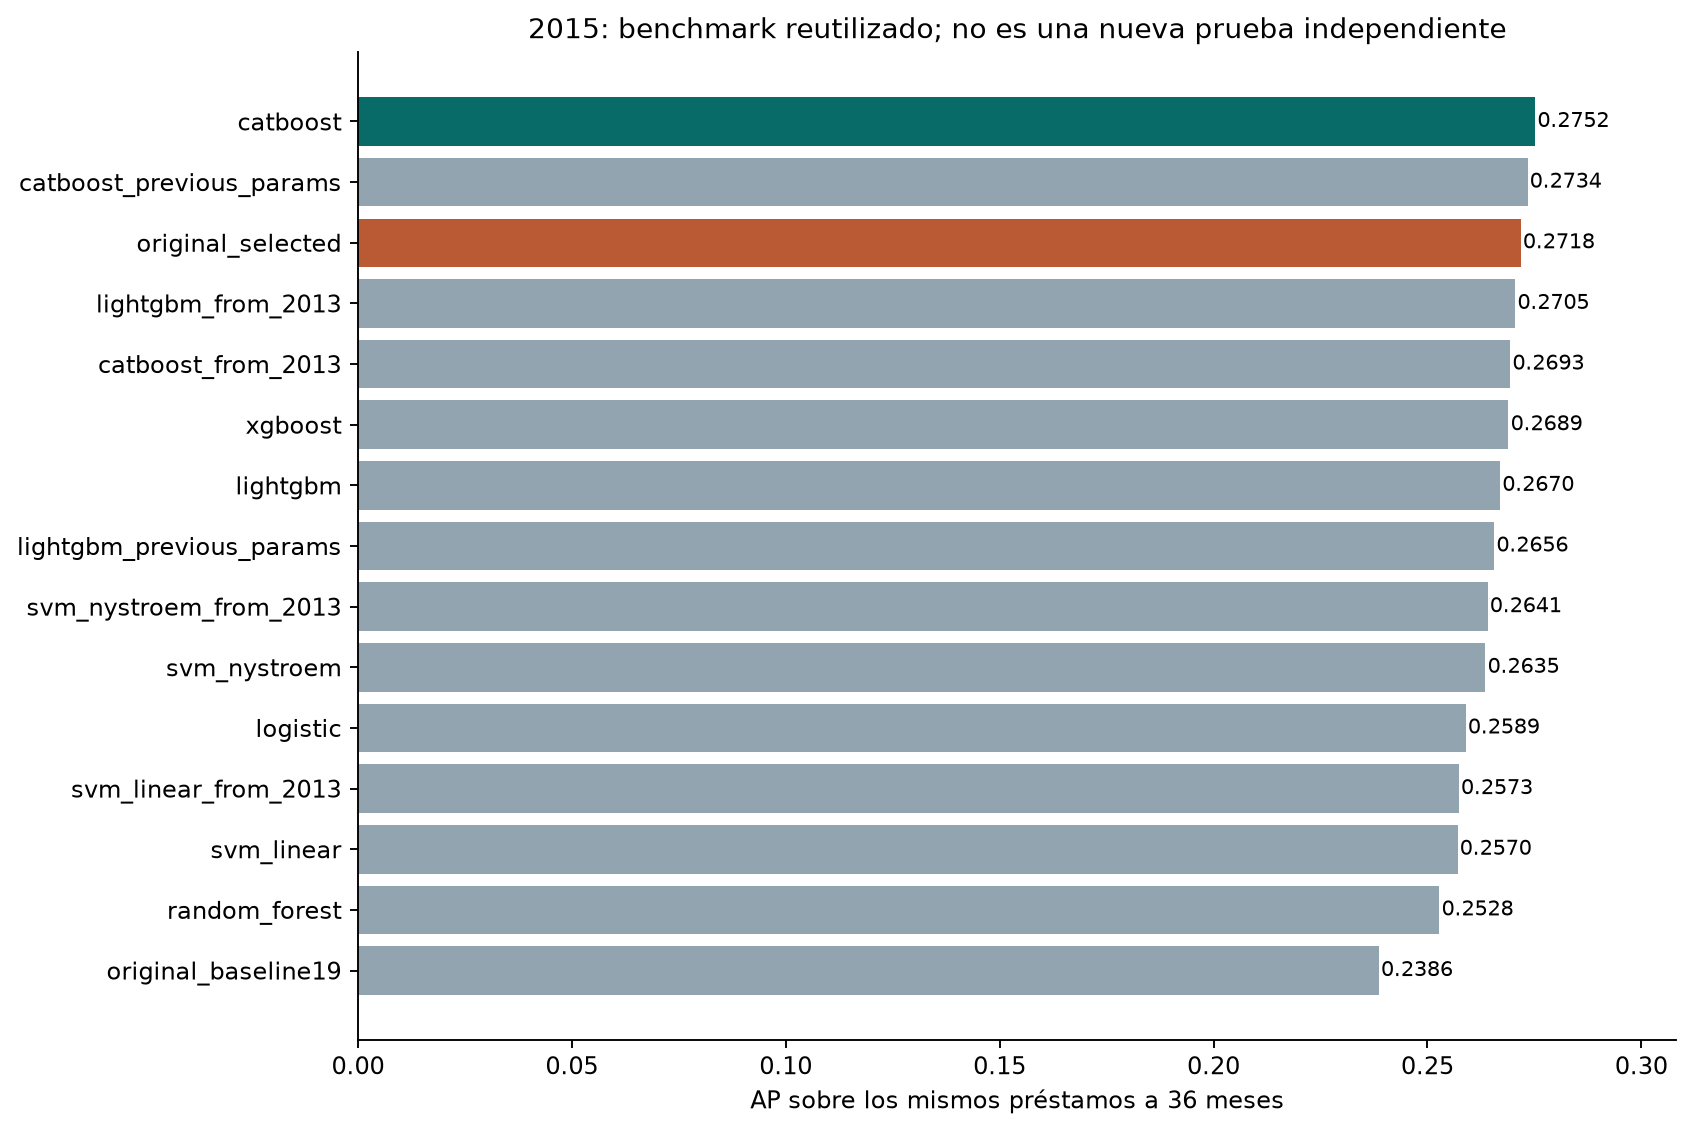

In [18]:
display(Image(filename=str(OUT/'figures'/'benchmark_maduro.png')))

In [19]:
common=pd.read_csv(OUT/'common_budget_benchmark.csv')
print('Comparación común: mismos 20.000 préstamos por año para todos, incluida SVM RBF exacta.')
display(common[['cohort','model','n','AP','ROC_AUC','Brier']].sort_values(['cohort','AP'],ascending=[True,False]))
print('La siguiente tabla usa las cohortes completas; omite RBF exactas no seleccionadas.')

Comparación común: mismos 20.000 préstamos por año para todos, incluida SVM RBF exacta.


,cohort,model,n,AP,ROC_AUC,Brier
3,2015,catboost,20000,0.288355,0.699388,0.118103
8,2015,catboost_previous_params,20000,0.287190,0.698963,0.118178
1,2015,original_selected,20000,0.284302,0.697029,0.118243
12,2015,lightgbm_from_2013,20000,0.281685,0.696242,0.118533
11,2015,xgboost,20000,0.281169,0.696050,0.118552
2,2015,lightgbm,20000,0.279565,0.698549,0.118129
13,2015,catboost_from_2013,20000,0.279505,0.699857,0.118198
7,2015,lightgbm_previous_params,20000,0.276921,0.697331,0.118424
6,2015,svm_nystroem,20000,0.267747,0.691518,0.118906
16,2015,svm_nystroem_from_2013,20000,0.266587,0.691612,0.118916


La siguiente tabla usa las cohortes completas; omite RBF exactas no seleccionadas.


In [20]:
benchmark=pd.read_csv(OUT/'benchmark_metrics.csv')
display(benchmark[['cohort','model','n','AP','raw_AP','ROC_AUC','Brier','precision','recall','recall_at_top20']])
print('Seleccionado en desarrollo:',conclusion['selected_on_development'])
print('Cambio pareado de AP frente al ensamble anterior:',conclusion['paired_AP_delta'])
print('IC condicional por bloques:',conclusion['month_block_conditional_CI_AP_delta'])
display(pd.read_csv(OUT/'benchmark_calibration_drift.csv'))
segments=pd.read_csv(OUT/'benchmark_segment_errors.csv')
display(segments.query("cohort==2015 and dimension in ['FICO','income'] and low_support==False")[[ 'model','dimension','segment','n','AP','FNR','FPR']])

,cohort,model,n,AP,raw_AP,ROC_AUC,Brier,precision,recall,recall_at_top20
0,2015,original_baseline19,258856,0.238625,0.238625,0.657901,0.121663,0.266130,0.294638,0.345845
1,2015,original_selected,258856,0.271797,0.271797,0.691953,0.118993,0.282460,0.390918,0.382028
2,2015,lightgbm,258856,0.266983,0.273622,0.693288,0.118920,0.252753,0.551194,0.385667
3,2015,catboost,258856,0.275187,0.275187,0.695059,0.118769,0.253165,0.555119,0.386629
4,2015,svm_linear,258856,0.257037,0.261673,0.685160,0.119748,0.242232,0.578566,0.374646
5,2015,svm_nystroem,258856,0.263544,0.271048,0.691263,0.119122,0.247417,0.575810,0.381872
6,2015,lightgbm_previous_params,258856,0.265605,0.270974,0.691492,0.119114,0.245291,0.581529,0.382106
7,2015,catboost_previous_params,258856,0.273392,0.273392,0.693766,0.118896,0.240690,0.616906,0.385355
8,2015,logistic,258856,0.258938,0.262807,0.685077,0.119686,0.240855,0.585662,0.374724
9,2015,random_forest,258856,0.252789,0.252789,0.674457,0.120519,0.224213,0.635258,0.362091


Seleccionado en desarrollo: catboost
Cambio pareado de AP frente al ensamble anterior: 0.0033899191301287046
IC condicional por bloques: {'low': 0.0018296353416589182, 'high': 0.004803653583408746}


,year,model,n,mean_prediction,observed_rate,observed_minus_prediction
0,2015,new_selected,258856,0.139546,0.148619,0.009073
1,2015,original_ensemble,258856,0.141951,0.148619,0.006668
2,2016,new_selected,212482,0.140044,0.198374,0.058330
3,2016,original_ensemble,212482,0.142638,0.198374,0.055736


,model,dimension,segment,n,AP,FNR,FPR
97,new_selected,FICO,"[720.0, 760.0)",34500,0.184686,0.822176,0.048147
98,new_selected,FICO,"[640.0, 680.0)",97479,0.306568,0.297510,0.476609
99,new_selected,FICO,"[760.0, inf)",12593,0.140054,0.922442,0.011679
100,new_selected,FICO,"[680.0, 720.0)",114284,0.249554,0.531202,0.243019
101,new_selected,income,"[120000.0, inf)",31776,0.233352,0.727566,0.090178
102,new_selected,income,"[40000.0, 80000.0)",125677,0.275467,0.446142,0.293970
103,new_selected,income,"[80000.0, 120000.0)",53393,0.245660,0.625175,0.151203
104,new_selected,income,"[-inf, 40000.0)",48010,0.306585,0.218668,0.571766
207,original_ensemble,FICO,"[720.0, 760.0)",34500,0.178058,0.926778,0.015491
208,original_ensemble,FICO,"[640.0, 680.0)",97479,0.303355,0.470472,0.314871


In [21]:
mature=pd.read_csv(OUT/'mature_secondary_metrics.csv')
if mature.empty:
    print('Ningún mes de 2016 cumplió el criterio de cobertura fijado.')
else:
    display(mature[['model','months','n','prevalence','AP','ROC_AUC','Brier','precision','recall']])

Ningún mes de 2016 cumplió el criterio de cobertura fijado.


### Interpretación del predictor seleccionado

Se permutan grupos de entradas originales en 5.000 préstamos de la validación temporal 2014 Q3, con tres repeticiones. La caída de AP describe cuánto depende el ordenamiento de cada grupo en ese conjunto; **no identifica causas del incumplimiento**. FICO bajo y alto se permutan juntos. Las variables derivadas se recalculan desde las entradas permutadas; predictores correlacionados pueden repartirse la importancia. Esta sensibilidad posterior no se usa para elegir ni reajustar el modelo.

In [22]:
display(pd.read_csv(OUT/'interpretability_validation.csv')[['model','feature_group','validation_n','baseline_AP','mean_AP_drop','permutation_sd']])

,model,feature_group,validation_n,baseline_AP,mean_AP_drop,permutation_sd
0,catboost,loan_amnt,5000,0.258134,0.029702,0.002108
1,catboost,FICO,5000,0.258134,0.020553,0.004026
2,catboost,annual_inc,5000,0.258134,0.014895,0.004854
3,catboost,total_acc,5000,0.258134,0.006350,0.000883
4,catboost,purpose,5000,0.258134,0.003122,0.003351
5,catboost,earliest_cr_line,5000,0.258134,0.002705,0.000363
6,catboost,dti,5000,0.258134,0.002629,0.002195
7,catboost,total_rev_hi_lim,5000,0.258134,0.002601,0.001371
8,catboost,revol_bal,5000,0.258134,0.002193,0.003766
9,catboost,revol_util,5000,0.258134,0.001899,0.001569


## 8. Sensibilidad a la información disponible

Se comparan las mismas filas y parámetros de LightGBM en validación 2014 Q3, con y sin `grade`, `sub_grade` e `int_rate` asignados por Lending Club. Es un diagnóstico de información adicional después de que la plataforma evaluó/clasificó el préstamo. Una mejora aquí no debe presentarse como mejor predicción independiente usando únicamente la solicitud. Este experimento no puede ganar la selección principal.

Como referencia del valor ya contenido en la evaluación de la plataforma, se añaden un ranking por tasa y una frecuencia de incumplimiento por subgrado aprendida en entrenamiento y suavizada hacia la media con 100 observaciones previas equivalentes. Su objetivo es evitar atribuir al nuevo algoritmo una señal que ya viene incorporada en el puntaje/precio de Lending Club.

También se mantiene el ensamble original y se ocultan campos de bureau que estaban ausentes en su entrenamiento, sobre una submuestra fija del benchmark reutilizado. Esto investiga sensibilidad al cambio de disponibilidad y al conteo derivado de ausentes; no valida una política de ocultar datos en producción.

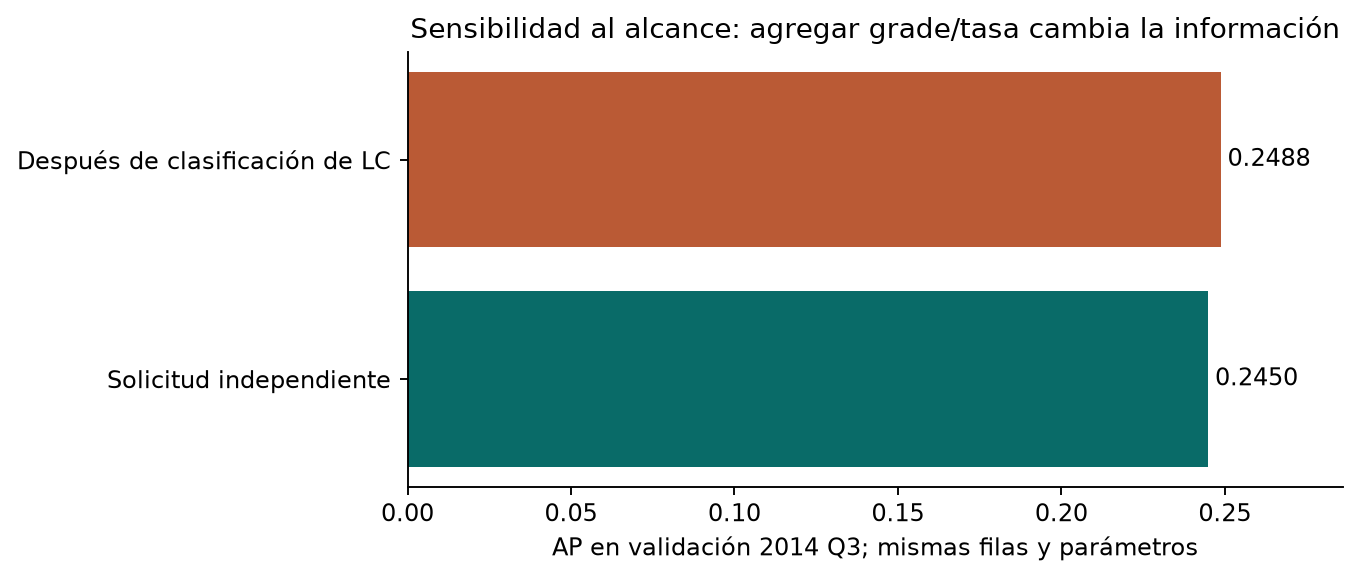

In [23]:
display(Image(filename=str(OUT/'figures'/'alcance_informacion.png')))

In [24]:
display(pd.read_csv(OUT/'information_scope_sensitivity.csv'))
display(pd.read_csv(OUT/'platform_score_baselines.csv'))
display(pd.read_csv(OUT/'original_model_missingness_probe.csv')[['scenario','n','AP','Brier','recall_at_top20']])

,scope,AP,ROC_AUC,train_n,validation_n,eligible_for_primary_selection,validation_cohort,added_inputs
0,independent_application_features,0.244987,0.683738,60000,40595,False,"2014 Q3, 36-month",NaN
1,after_LC_grading_DIAGNOSTIC_ONLY,0.248808,0.687609,60000,40595,False,"2014 Q3, 36-month","grade, sub_grade, int_rate"


,strategy,AP,ROC_AUC,scope,validation_n,eligible_for_primary_selection
0,LC_interest_rate_rank_only,0.213081,0.657358,"after platform scoring, diagnostic only",40595,False
1,training_subgrade_frequency_only,0.197931,0.650646,"after platform scoring, diagnostic only",40595,False


,scenario,n,AP,Brier,recall_at_top20
0,unchanged,20000,0.284302,0.118243,0.395020
1,mask_previously_unavailable_bureau,20000,0.284252,0.118246,0.394347


## 9. Conclusiones y trabajo pendiente

Se distinguen problemas de validez de población de mejoras predictivas. La cobertura desigual y la disponibilidad temporal de variables están verificadas. Los errores de dominio comprobados son escasos; no se justifica prometer una mejora grande por corregirlos. La muestra representa razonablemente sus marginales terminales, pero no a todos los aceptados.

Las tablas anteriores determinan si las recetas, el ajuste y SVM mejoran realmente las métricas bajo un alcance comparable. Una hipótesis puede estar respaldada, no respaldada o seguir sin identificarse: no se fuerza una conclusión favorable.

La comparación con información de la plataforma cambia el problema y se mantiene separada. Para una nueva confirmación final hacen falta desenlaces maduros no utilizados, junto con fechas fiables de resultado. Sin ellos no se demuestra desempeño entre todos los préstamos activos ni se reconstruye un backtest operativo.

Fuentes y decisiones: [bitácora de esta fase](../experiments/research_v2_notes.md), [protocolo v2](../experiments/protocol_v2.json), [documentación SVC](https://scikit-learn.org/stable/modules/generated/sklearn.svm.SVC.html), [aproximación de kernels](https://scikit-learn.org/stable/modules/kernel_approximation.html).

In [25]:
with pd.option_context('display.max_colwidth',180):
    display(pd.read_csv(OUT/'hypothesis_results.csv'))

,hypothesis,finding,predictive_test
0,Faltantes estructurales afectan la información disponible,Confirmado: 17 columnas constantes o >95% ausentes en entrenamiento anterior.,Imputación con indicadores: cambio medio CV AP -0.001130. La estructura por sí sola no prueba daño predictivo.
1,Excluir préstamos activos limita la generalización,Confirmado: cobertura 2015/36 = 99.9481%; 2016/36 = 71.8258%.,No se identifica el resultado futuro de activos. Se define población madura; no se inventan etiquetas.
2,La frecuencia de incumplimiento cambia entre años maduros,Confirmado descriptivamente: 2013/36 = 12.3260%; 2015/36 = 14.8863%.,Se prueban fechas de entrenamiento y validación temporal. No se atribuye causalidad al año.
3,La muestra inicial está mal tomada de su población terminal,No respaldado por las marginales revisadas: TVD año = 0.002714.,No demuestra representatividad conjunta ni permite extrapolar a todos los aceptados o rechazados.
4,Ajustar hiperparámetros mejora con las mismas filas y entradas,catboost: AP +0.002285; lightgbm: AP +0.003458,Comparación controlada en 2014 Q3; no equivale a confirmación externa independiente.
5,SVM supera las otras estrategias en la selección temporal,Mejor SVM AP = 0.251163; mejor candidato AP = 0.253568.,Incluye controles con mismas 12000 filas y benchmark común de 20000; el costo de RBF queda explícito.
6,La nueva selección supera al ensamble anterior en la cohorte comparable,AP 0.271797 → 0.275187; cambio +0.003390.,"2015/36 reutilizado, no prueba nueva independiente. Ver intervalo pareado y métricas de calibración."


In [26]:
print('Seleccionado en desarrollo:',conclusion['selected_on_development'])
print(f"AP en la cohorte madura reutilizada: {conclusion['original_ensemble_AP']:.4f} → {conclusion['new_AP']:.4f}; cambio {conclusion['paired_AP_delta']:+.4f}.")
interval=conclusion['month_block_conditional_CI_AP_delta']
print(f"Intervalo bootstrap condicional por meses: [{interval['low']:+.4f}, {interval['high']:+.4f}].")
if conclusion['paired_AP_delta']<=0:
    print('La nueva selección no supera al ensamble anterior en AP sobre esta cohorte; no se justifica afirmar una mejora por ese criterio.')
elif interval['low']<=0:
    print('Hay mejora puntual, pero el intervalo condicional incluye cero. No se afirma una mejora robusta ni una confirmación independiente.')
else:
    print('El cambio es positivo bajo este remuestreo condicional. La reutilización del benchmark y las decisiones previas limitan la confirmación externa.')
print('Cambios de AP por hiperparámetros, con mismas filas y variables:',conclusion['hyperparameter_validation_AP_delta'])
print('Cambio medio de AP al imputar con indicadores:',conclusion['median_imputation_mean_CV_AP_delta'])
print('Ganancia de AP al agregar información asignada por LC, solo en diagnóstico de validación:',conclusion['validation_AP_gain_with_LC_assigned_information'])
print('Ese cambio de información no es elegible como mejora del modelo independiente principal.')
display(pd.Series(conclusion,name='resultado'))
print(json.loads((OUT/'benchmark_receipt.json').read_text(encoding='utf-8')))

Seleccionado en desarrollo: catboost
AP en la cohorte madura reutilizada: 0.2718 → 0.2752; cambio +0.0034.
Intervalo bootstrap condicional por meses: [+0.0018, +0.0048].
El cambio es positivo bajo este remuestreo condicional. La reutilización del benchmark y las decisiones previas limitan la confirmación externa.
Cambios de AP por hiperparámetros, con mismas filas y variables: {'catboost': 0.0022850667210855824, 'lightgbm': 0.0034581066203854816}
Cambio medio de AP al imputar con indicadores: -0.0011295605858984703
Ganancia de AP al agregar información asignada por LC, solo en diagnóstico de validación: 0.003820352568557006
Ese cambio de información no es elegible como mejora del modelo independiente principal.


selected_on_development                                                                         catboost
recipe                                                 {'name': 'stable_36_recent', 'mode': 'stable',...
screened_recipe                                        {'name': 'stable_36_recent', 'mode': 'stable',...
primary_scope                                                same 2015 36-month cohort, reused benchmark
new_AP                                                                                          0.275187
original_ensemble_AP                                                                            0.271797
paired_AP_delta                                                                                  0.00339
new_ROC_AUC                                                                                     0.695059
original_ROC_AUC                                                                                0.691953
new_Brier                                              

{'state': 'complete', 'completed_utc': '2026-11-02T19:53:26.919535+00:00', 'role': '2015/2016 are reused, previously observed retrospective benchmarks, NOT pristine independent final tests. The original experiment and metrics remain immutable.', 'lock_sha256': '0ddbbeae2d84de5a4483d2efeb1685007d46e70ab0cf78272f90e78f4e147e49', 'selected': 'catboost', 'metrics_sha256': '816f8a1a18243bf4ab5f42a3f0017ed04f944e092fcd50365b90f3f97f24260f', 'pristine_final_test': False}


### Continuación experimental: optimización predictiva

La investigación posterior está en [07_optimizacion_predictiva.ipynb](07_optimizacion_predictiva.ipynb). Compara nuevas variables, preparación específica, datos de entrenamiento, hiperparámetros y ensambles con la referencia CatBoost de la fase 2. Los resultados históricos de este notebook se conservan; 2015/2016 son benchmarks reutilizados en esa continuación, no una nueva prueba independiente. El informe final aún no se ha elaborado.